# Milestone 1: implementation


In [41]:
import random
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.optim import AdamW
from tqdm.auto import tqdm, tqdm
from math import exp
from pathlib import Path
import os
import h5py

def seed_everything(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Reference: ScoreMD evaluation/evaluate_aldp.py, lines 72-79.
plt.style.use("tableau-colorblind10")

SEED = 42
seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [42]:
DATA_DIR = Path("/Users/user/PML_Space_Time_Diffusion/data")
OUTPUT_DIR = Path("/Users/user/PML_Space_Time_Diffusion/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Müller–Brown potential

In [43]:
def mueller_brown_potential(xs: torch.Tensor, beta: float = 1.0) -> torch.Tensor:
    """Compute the Müller-Brown potential energy."""
    x, y = xs[:, 0], xs[:, 1]
    e1 = -200 * torch.exp(-((x - 1) ** 2) - 10 * y**2)
    e2 = -100 * torch.exp(-(x**2) - 10 * (y - 0.5) ** 2)
    e3 = -170 * torch.exp(-6.5 * (0.5 + x) ** 2 + 11 * (x + 0.5) * (y - 1.5) - 6.5 * (y - 1.5) ** 2)
    e4 = 15.0 * torch.exp(0.7 * (1 + x) ** 2 + 0.6 * (x + 1) * (y - 1) + 0.7 * (y - 1) ** 2)
    return beta * (e1 + e2 + e3 + e4)


def mueller_brown_force(xs: torch.Tensor, beta: float = 1.0) -> torch.Tensor:
    """Compute the analytic force as the negative gradient of the potential."""
    x, y = xs[:, 0], xs[:, 1]
    e1 = -200 * torch.exp(-((x - 1) ** 2) - 10 * y**2)
    e2 = -100 * torch.exp(-(x**2) - 10 * (y - 0.5) ** 2)
    e3 = -170 * torch.exp(-6.5 * (0.5 + x) ** 2 + 11 * (x + 0.5) * (y - 1.5) - 6.5 * (y - 1.5) ** 2)
    e4 = 15.0 * torch.exp(0.7 * (1 + x) ** 2 + 0.6 * (x + 1) * (y - 1) + 0.7 * (y - 1) ** 2)
    force_x = -(e1 * (-2 * (x - 1)) + e2 * (-2 * x) + e3 * (-13 * (x + 0.5) + 11 * (y - 1.5)) + e4 * (1.4 * (x + 1) + 0.6 * (y - 1)))
    force_y = -(e1 * (-20 * y) + e2 * (-20 * (y - 0.5)) + e3 * (11 * (x + 0.5) - 13 * (y - 1.5)) + e4 * (0.6 * (x + 1) + 1.4 * (y - 1)))
    return beta * torch.stack([force_x, force_y], dim=-1)

**Observation**: The dtype has a large effect on the force difference

In [44]:
# Draw samples s.t. x in [-1.5, 1.1] and y in [-0.4, 2.2]
xs = torch.rand(256, 2, dtype=torch.float32)
xs = 2.6 * xs + torch.tensor([-1.5, -0.4], dtype=xs.dtype)
xs.requires_grad_(True)
energies = mueller_brown_potential(xs)
force_autograd = -torch.autograd.grad(energies.sum(), xs)[0]
force_error = (mueller_brown_force(xs) - force_autograd).abs()
print("Force MAE:", force_error.mean().item())
print("Maximum force error:", force_error.max().item())

Force MAE: 1.5309895388782024e-05
Maximum force error: 0.00048828125


In [45]:
# Draw samples s.t. x in [-1.5, 1.1] and y in [-0.4, 2.2]
xs = torch.rand(256, 2, dtype=torch.float64)
xs = 2.6 * xs + torch.tensor([-1.5, -0.4], dtype=xs.dtype)
xs.requires_grad_(True)
energies = mueller_brown_potential(xs)
force_autograd = -torch.autograd.grad(energies.sum(), xs)[0]
force_error = (mueller_brown_force(xs) - force_autograd).abs()
print("Force MAE:", force_error.mean().item())
print("Maximum force error:", force_error.max().item())

Force MAE: 2.812387909362224e-14
Maximum force error: 9.094947017729282e-13


## Langevin simulation


In [46]:
@torch.no_grad()
def langevin_integrator(x0, v0, force_fn, dt, n_steps, kbT=1.0, gamma=1.0, mass=1.0, save_every=1):
    """Return positions saved every save_every steps of underdamped Langevin dynamics."""
    x, v = x0.clone(), v0.clone()
    mass = torch.as_tensor(mass, device=x.device, dtype=x.dtype)
    alpha = exp(-gamma * dt)
    f_scale = (1 - alpha) / gamma
    noise_std = torch.sqrt(kbT * (1 - alpha**2) / mass)
    
    trajectory = []
    for step in tqdm(range(n_steps), desc="Simulating"):
        new_v_det = alpha * v + f_scale * force_fn(x) / mass
        new_v = new_v_det + noise_std * torch.randn_like(x)
        x, v = x + dt * new_v, new_v
        if (step + 1) % save_every == 0:
            trajectory.append(x)

    return torch.stack(trajectory)

kbT = 23.0
mass = 0.5
num_mueller_brown_samples = 50_000
num_mueller_brown_steps = 5  # decorrelates the data a bit
burn_in = 5000 # let system equilibrate before saving samples

simulation_config = dict(
    dt=5e-3, 
    n_steps=burn_in + num_mueller_brown_samples * num_mueller_brown_steps,
    kbT=kbT, 
    gamma=1.0, 
    mass=mass, 
    save_every=num_mueller_brown_steps
)

x0 = torch.tensor([[-0.55828035, 1.44169]], dtype=torch.float32)
v0 = torch.sqrt(torch.tensor(kbT / mass)) * torch.randn_like(x0)
md_trajectory = langevin_integrator(x0, v0, mueller_brown_force, **simulation_config)
md_trajectory = md_trajectory[burn_in // num_mueller_brown_steps:]
trajectory = md_trajectory[:, 0]
print("Trajectory shape:", trajectory.shape)

path = DATA_DIR / "mueller_brown" / "traj0.h5"
path.parent.mkdir(parents=True, exist_ok=True)
with h5py.File(path, "w") as data:
    data.create_dataset("coordinates", data=trajectory.numpy())

Simulating: 0it [1:08:56, ?it/s]
Simulating: 100%|██████████| 255000/255000 [00:38<00:00, 6685.68it/s]


Trajectory shape: torch.Size([50000, 2])


## Lazy data loading

In [47]:
def load_data(dataset="aldp", transformation=None, n_train=None, n_test=None, root=DATA_DIR):
    """Return lazy training and test generators."""
    paths = {
        "aldp": "aldp/AImplicitUnconstrained/traj0.h5", 
        "mueller_brown": "mueller_brown/traj0.h5"
    }
    path = Path(root) / paths[dataset]
    with h5py.File(path, "r") as data:
        n_samples = len(data["coordinates"])
        
    n_train = int(0.8 * n_samples) if n_train is None else n_train
    n_test = n_samples - n_train if n_test is None else n_test

    def generate(start, stop):
        with h5py.File(path, "r") as data:
            for i in range(start, stop):
                sample = torch.from_numpy(data["coordinates"][i].copy()).float()
                yield transformation(sample) if transformation is not None else sample

    return generate(0, n_train), generate(n_samples - n_test, n_samples)


train_generator, test_generator = load_data("mueller_brown")
train_data = torch.stack(list(train_generator))
test_data = torch.stack(list(test_generator))
print("Training samples:", len(train_data), "| Test samples:", len(test_data))

Training samples: 40000 | Test samples: 10000


## Density plots

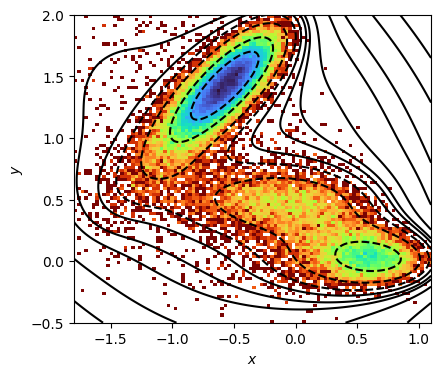

In [48]:
def plot_mueller_brown(samples):
    grid_size = 150
    (x_min, x_max), (y_min, y_max) = np.array([[-1.8, 1.1], [-0.5, 2.0]])
    x, y = torch.linspace(x_min, x_max, grid_size), torch.linspace(y_min, y_max, grid_size)
    x, y = torch.meshgrid(x, y, indexing="ij")
    z = mueller_brown_potential(torch.stack([x, y], -1).reshape(-1, 2)).reshape([grid_size, grid_size])
    plt.contour(x, y, z, levels=[-120, -90, -50, -20, 0, 20, 35, 70, 150, 250, 500, 1000], colors="black")
    samples = samples.detach().cpu().numpy()
    plt.hist2d(
        samples[:, 0], 
        samples[:, 1], 
        bins=100, 
        range=[[x_min, x_max], [y_min, y_max]],
        norm=mpl.colors.LogNorm(), 
        cmap="turbo_r", 
        rasterized=True
    )
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.gca().set_aspect("equal")


def plot_density(samples, dataset="mueller_brown"):
    """Plot (x, y) or (phi, psi) samples of shape (N, 2)."""
    if dataset == "mueller_brown":
        plot_mueller_brown(samples)
    else:
        angles = samples.detach().cpu().numpy()
        plt.hist2d(
            angles[:, 0], 
            angles[:, 1], 
            bins=60, 
            range=[[-np.pi, np.pi], [-np.pi, np.pi]],
            norm=mpl.colors.LogNorm(), 
            cmap="turbo_r", 
            rasterized=True
        )
        ticks = [-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi]
        labels = [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"]
        plt.xticks(ticks, labels)
        plt.yticks(ticks, labels)
        plt.xlabel(r"$\varphi$")
        plt.ylabel(r"$\psi$")
        plt.gca().set_aspect("equal")


plt.figure(figsize=(5, 4))
plot_mueller_brown(trajectory)
plt.gcf().savefig(OUTPUT_DIR / "md_density.pdf", bbox_inches="tight", dpi=300)
plt.gcf().savefig(OUTPUT_DIR / "md_density.png", bbox_inches="tight", dpi=180)
plt.show()

## Energy-based model and VP process

In [49]:
class Model(nn.Module):
    """Energy-based MLP; score is -grad_x E_theta (x, t)."""
    
    def __init__(self, dim=2, hidden_dim=92, n_layers=3):
        super().__init__()
        self.dim = dim

        layers = []
        in_dim = dim + 1 # data dims + noise level
        for _ in range(n_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.SiLU())
            in_dim = hidden_dim
        layers.append(nn.Linear(in_dim, 1))
        self.mlp = nn.Sequential(*layers)

    def energy(self, x: torch.Tensor, t: torch.Tensor):
        """Return the energy E_theta(x, t) with shape (N,)."""
        h = torch.cat([x, t.reshape(-1, 1)], dim=-1) # (N, dim + 1)
        h = self.mlp(h)  # (N, 1)
        return h.squeeze(-1)  # (N,)

    def forward(self, x: torch.Tensor, t: torch.Tensor, create_graph: bool = True):
        """Return the score s_theta(x, t) = -grad_x E_theta (x, t) with shape (N, dim)."""
        x.requires_grad_(True)
        e = self.energy(x, t)
        # we only need create_graph if we want the gradient of the score (i.e. during training)
        return -torch.autograd.grad(e.sum(), x, create_graph=create_graph)[0]

In [50]:
def get_linear_beta_function(beta_min: float, beta_max: float):
    """
    Returns:
        beta(t): Linear beta schedule as a function of time.
        log_mean_coeff(t): Logarithm of the mean coefficient in the VP SDE.
    """

    def beta(t):
        return beta_min + t * (beta_max - beta_min)

    def log_mean_coeff(t):
        return -0.5 * t * beta_min - 0.25 * t**2 * (beta_max - beta_min)

    return beta, log_mean_coeff


class VP:
    """Variance preserving (VP) SDE, a.k.a. time rescaled Ohrnstein Uhlenbeck (OU) SDE."""

    def __init__(self, beta_min: float = 0.1, beta_max: float = 20.0):
        self.beta, self.log_mean_coeff = get_linear_beta_function(
            beta_min=beta_min, 
            beta_max=beta_max
        )

    def sde(self, x, t):
        beta_t = self.beta(t)
        diffusion = torch.sqrt(beta_t)
        drift = -0.5 * beta_t[:, None] * x
        return drift, diffusion

    def std(self, t):
        return torch.sqrt(self.variance(t))

    def variance(self, t):
        return 1.0 - torch.exp(2 * self.log_mean_coeff(t))

    def marginal_prob(self, x, t):
        """Mean and std of the marginal at time t."""
        mean_coeff = torch.exp(self.log_mean_coeff(t))
        return mean_coeff * x, self.std(t)

    def reverse_sde(self, x, t, score):
        """Compute the reverse-time drift and diffusion from a score tensor."""
        drift, diffusion = self.sde(x, t)
        drift = -drift + diffusion[:, None] ** 2 * score
        return drift, diffusion


# Define the VP SDE with common choices for beta_min and beta_max
vp = VP(beta_min=0.1, beta_max=20.0)

In [51]:
def perturb(t, data):
    """
    Perturb the data x(0) using the forward SDE to get x(t).

    Returns:
        x_t: noisy sample
        noise: sampled noise
        std: standard deviation at time t
    """
    mean, std = vp.marginal_prob(data, t)
    noise = torch.randn_like(data)
    return mean + std * noise, noise, std


def errors(noise, score, std):
    return noise + std * score


def diffusion_loss_fn(batch, ts, model):
    x_t, noise, std = perturb(ts, batch)
    score = model(x_t, ts)
    e = errors(noise, score, std)

    return torch.mean(e**2)

## Training

Training uses 100 epochs, batches of 512 and AdamW with learning rate
$3\times10^{-4}$. A

100%|██████████| 100/100 [00:13<00:00,  7.23it/s]


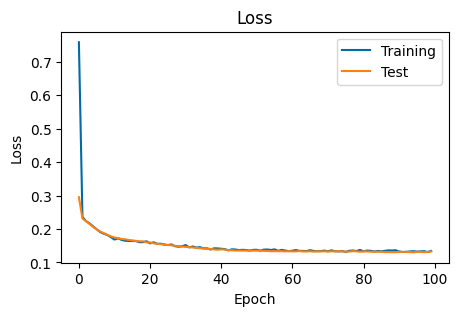

Final Loss: {'train': 0.13444979336017218, 'validation': 0.13291966915130615}


In [52]:
def train_loop(data, loss_fn, epochs, BS, model, optimizer, validation_data):
    losses = []
    validation_losses = []
    model.train()
    
    # We use fixed noise levels for validatioon
    validation_data = validation_data[:2048].to(device)
    validation_rng = torch.Generator(device=device).manual_seed(SEED + 1)
    validation_t = torch.rand(len(validation_data), 1, device=device, generator=validation_rng) * (1 - 1e-5) + 1e-5
    validation_noise = torch.randn(validation_data.shape, device=device, generator=validation_rng)
    mean, std = vp.marginal_prob(validation_data, validation_t)
    validation_x = mean + std * validation_noise

    def step(optimizer, model, data, idx):
        batch = data[idx].to(device)
        ts = torch.rand(BS, 1, device=device) * (1 - 1e-5) + 1e-5
        loss = loss_fn(batch, ts, model)
        loss.backward()
        optimizer.step()
        return loss

    for _ in tqdm(range(epochs)):
        perm = torch.randperm(data.size(0))[: data.size(0) // BS * BS]
        perm = perm.reshape(-1, BS)

        epoch_losses = []
        for idx in perm:
            optimizer.zero_grad()
            loss = step(optimizer, model, data, idx)
            epoch_losses.append(loss.item())

        losses.append(np.mean(epoch_losses))
        score = model(validation_x.detach(), validation_t, create_graph=False)
        valdation_loss = torch.mean(errors(validation_noise, score, std)**2)
        validation_losses.append(valdation_loss.item())

    return {"train": losses, "validation": validation_losses}


model = Model(dim=2, hidden_dim=92, n_layers=3).to(device)
optimizer = AdamW(model.parameters(), lr=3e-4)

history = train_loop(train_data, diffusion_loss_fn, 100, 512, model, optimizer, test_data)
torch.save(model.state_dict(), OUTPUT_DIR / "model.pt")
plt.figure(figsize=(5, 3))
plt.title("Loss")
plt.plot(history["train"], label="Training")
plt.plot(history["validation"], label="Test")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.gcf().savefig(OUTPUT_DIR / "training_loss.pdf", bbox_inches="tight", dpi=300)
plt.gcf().savefig(OUTPUT_DIR / "training_loss.png", bbox_inches="tight", dpi=180)
plt.show()
print("Final Loss:", {key: values[-1] for key, values in history.items()})

## Sampling and learned energy landscapes

The sampler follows tutorial cell 15. It uses 200 Euler–Maruyama intervals, stops at
$t=10^{-5}$ and detaches the state after every step. Using intervals avoids the tutorial's
extra endpoint update. Energy contours follow the spacetime repository's `contourf` style.

Sampling: 100%|██████████| 200/200 [00:05<00:00, 37.60it/s]


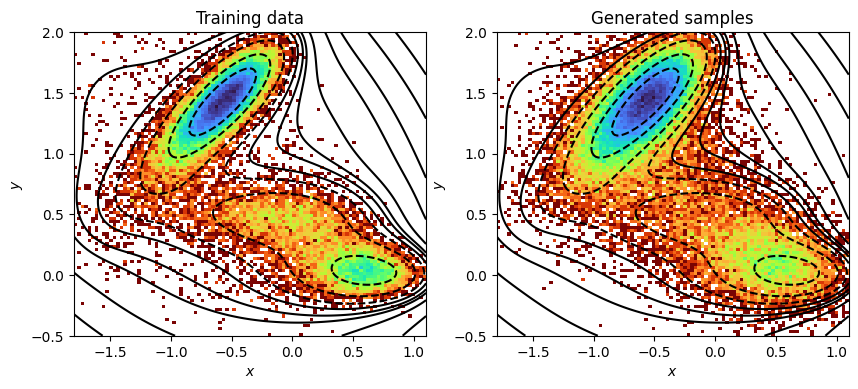

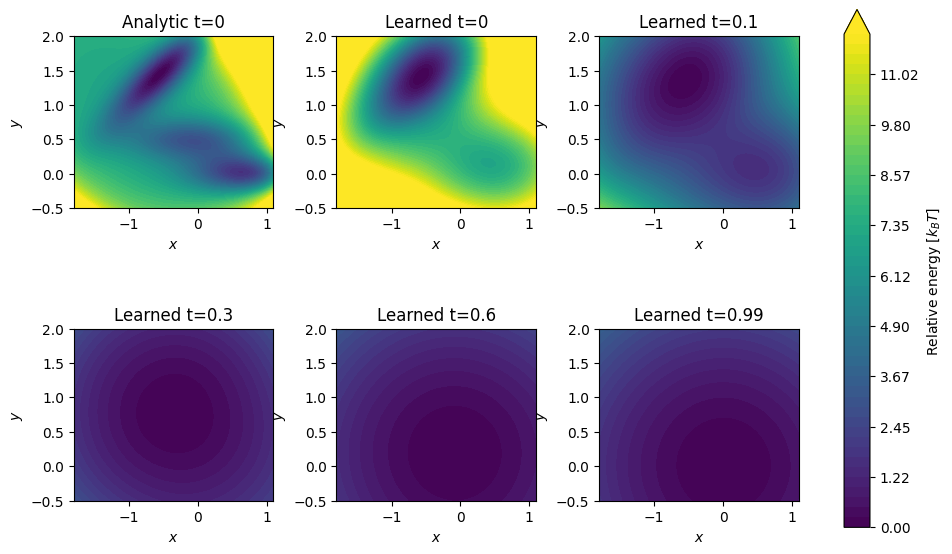

In [53]:
@torch.no_grad()
def sample(model, num_samples, num_steps, eps=1e-5):
    model.eval()
    ts = torch.linspace(1, eps, num_steps + 1, device=device)
    x = torch.randn(num_samples, 2, device=device)

    for i in tqdm(range(num_steps), desc="Sampling"):
        t = torch.full((num_samples,), ts[i].item(), device=device)
        dt = ts[i] - ts[i + 1]
        # enable gradient computation to compute the energy
        with torch.enable_grad():
            score = model(x, t, create_graph=False)
        drift, diffusion = vp.reverse_sde(x, t, score)
        x_mean = x + drift * dt
        x = x_mean + diffusion[:, None] * torch.sqrt(dt) * torch.randn_like(x)

    return x


generated = sample(model, num_samples=50_000, num_steps=200)
np.save(OUTPUT_DIR / "generated_samples.npy", generated.numpy())
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Training data")
plot_mueller_brown(train_data)
plt.subplot(1, 2, 2)
plt.title("Generated samples")
plot_mueller_brown(generated)
plt.gcf().savefig(OUTPUT_DIR / "density_comparison.pdf", bbox_inches="tight", dpi=300)
plt.gcf().savefig(OUTPUT_DIR / "density_comparison.png", bbox_inches="tight", dpi=180)
plt.show()

# Reference: spacetime molecular_experiments/mol_utils.py, lines 361-370.
x = torch.linspace(-1.8, 1.1, 150)
y = torch.linspace(-0.5, 2.0, 150)
grid_x, grid_y = torch.meshgrid(x, y, indexing="ij")
grid = torch.stack([grid_x, grid_y], dim=-1).reshape(-1, 2)
noise_levels = [0.0, 0.1, 0.3, 0.6, 0.99]
with torch.no_grad():
    energies = [mueller_brown_potential(grid) / kbT]
    for t in noise_levels:
        times = torch.full((len(grid), 1), t, device=device)
        energies.append(model.energy(grid.to(device), times).cpu())

plt.figure(figsize=(10, 6))
for i, (energy, title) in enumerate(zip(energies, ["Analytic t=0"] + [f"Learned t={t:g}" for t in noise_levels])):
    plt.subplot(2, 3, i + 1)
    energy = (energy - energy.min()).reshape(150, 150)
    contours = plt.contourf(grid_x, grid_y, energy, levels=np.linspace(0, 12, 50), extend="max")
    contours.set_zorder(0)
    plt.gca().set_rasterization_zorder(1)
    plt.title(title)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.gca().set_aspect("equal")
plt.tight_layout()
plt.colorbar(contours, ax=plt.gcf().axes, label=r"Relative energy [$k_BT$]")
plt.gcf().savefig(OUTPUT_DIR / "learned_noised_energies.pdf", bbox_inches="tight", dpi=300)
plt.gcf().savefig(OUTPUT_DIR / "learned_noised_energies.png", bbox_inches="tight", dpi=180)
plt.show()

## Download Alanine dipeptide

In [ ]:
def download_aldp(root):
    """Download ScoreMD's AImplicitUnconstrained trajectory and matching OpenMM system."""
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    trajectory_file = root / "AImplicitUnconstrained" / "traj0.h5"
    if trajectory_file.exists() and (trajectory_file.parent / "system.xml").exists() and (trajectory_file.parent / "reference.pdb").exists():
        return trajectory_file

    from bgmol.datasets import AImplicitUnconstrained
    from bgmol.systems.minipeptides import MiniPeptide
    from bgmol.tpl.download import download_and_extract_archive
    from openmm import XmlSerializer, app, unit

    # Reference: ScoreMD src/scoremd/data/dataset/aldp.py:L60-L69 uses AImplicitUnconstrained.
    # Deviation: read=False avoids eager trajectory loading; h5py below reads selected frames.
    # Deviation: use HTTPS for BGMol's legacy download URLs.
    MiniPeptide.url = MiniPeptide.url.replace("http://", "https://", 1)
    dataset = AImplicitUnconstrained(root=str(root), download=False, read=False)
    if not trajectory_file.exists():
        # Deviation from BGMol datasets/base.py:L63-L69: retain the downloaded archive.
        download_and_extract_archive(dataset.url.replace("http://", "https://", 1), str(root), md5=dataset.md5, remove_finished=False)

    (trajectory_file.parent / "system.xml").write_text(XmlSerializer.serialize(dataset.system.system))
    with (trajectory_file.parent / "reference.pdb").open("w") as stream:
        app.PDBFile.writeFile(
            dataset.system.topology, 
            dataset.system.positions * unit.nanometer, 
            stream
        )
        
    return trajectory_file


def compute_dihedrals(positions, phi_indices, psi_indices):
    # Reference: mdtraj/geometry/dihedral.py:L64-L79 uses the same atan2 convention.
    atom_indices = [phi_indices, psi_indices]
    p0, p1, p2, p3 = positions[..., atom_indices, :].unbind(dim=-2)
    b0 = p0 - p1
    b1 = p2 - p1
    b2 = p3 - p2
    b1 = b1 / torch.linalg.vector_norm(b1, dim=-1, keepdim=True).clamp_min(1e-12)
    v = b0 - (b0 * b1).sum(dim=-1, keepdim=True) * b1
    w = b2 - (b2 * b1).sum(dim=-1, keepdim=True) * b1
    x = (v * w).sum(dim=-1)
    y = (torch.linalg.cross(b1, v, dim=-1) * w).sum(dim=-1)
    return torch.atan2(y, x)

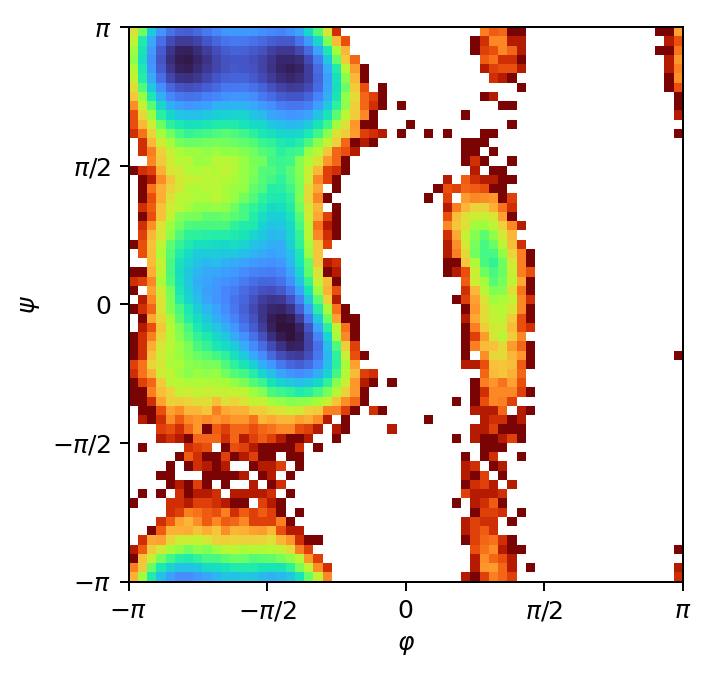

In [ ]:
aldp_path = download_aldp(DATA_DIR / "aldp")

phi_indices = [4, 6, 8, 14]
psi_indices = [6, 8, 14, 16]
aldp_train, aldp_test = load_data(
    "aldp", 
    transformation=lambda xs: compute_dihedrals(xs, phi_indices, psi_indices)
)
samples = torch.stack(list(aldp_train) + list(aldp_test))

plt.figure(figsize=(5, 4))
plot_density(samples, dataset="aldp")
plt.gcf().savefig(OUTPUT_DIR / "aldp_density.pdf", bbox_inches="tight", dpi=300)
plt.gcf().savefig(OUTPUT_DIR / "aldp_density.png", bbox_inches="tight", dpi=180)
plt.show()